# DS1 Naive Bayes

Classifies DS1 patients as CKD or not CKD with Naive Bayes, which applies Bayes' theorem under the assumption that features are independent given the class. The only input is the preprocessed train/test split from `Data_Preprocessing.ipynb` (`3_preprocessed_data/`), found through `configs/config.json`. Every choice is made with cross-validation on the training set; the test set is used once, at the end.

| Step | What it does |
|---|---|
| 1 | Load the preprocessed data |
| 2 | Check the independence assumption |
| 3 | Baseline Gaussian NB |
| 4 | Tune the variance smoothing |
| 5 | Let Naive Bayes pick its own features |
| 6 | Model binary features as binary (mixed NB) |
| 7 | Check the scores are stable |
| 8 | Look at the errors on the training folds |
| 9 | Evaluate the final model on the test set |
| 10 | Compare all versions |
| 11 | Practical application and related work |

## 1. Load the preprocessed data

We load the preprocessed train and test sets with all 30 features. File paths come from the config, and labels are mapped to 0/1 in the config order (ckd = 0, notckd = 1). Gaussian NB fits one mean and variance per feature and class, so scaling does not change its predictions; the missing-value imputation done in preprocessing is what matters here.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.model_selection import GridSearchCV, StratifiedKFold, RepeatedStratifiedKFold, cross_val_score, cross_val_predict
from sklearn.naive_bayes import GaussianNB, BernoulliNB
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

root = Path.cwd()
while not (root / "configs" / "config.json").is_file():
    root = root.parent

config = json.loads((root / "configs" / "config.json").read_text())
ds = config["datasets"]["list"]["DS1"]
base = (root / "configs" / config["paths"]["datasets_dir"] / ds["folder"]).resolve()
target = ds["target"]["column"]
class_order = ds["target"]["values"]
RANDOM_STATE = config["training"]["random_state"]
train = pd.read_csv(base / ds["files"]["preprocessed"]["train"])
test = pd.read_csv(base / ds["files"]["preprocessed"]["test"])

X_train, X_test = train.drop(columns=[target]), test.drop(columns=[target])
y_train = train[target].map({c: i for i, c in enumerate(class_order)})
y_test = test[target].map({c: i for i, c in enumerate(class_order)})

binary_cols = [c for c in X_train.columns if set(X_train[c].unique()) <= {0.0, 1.0}]
continuous_cols = [c for c in X_train.columns if c not in binary_cols]

print("Train:", X_train.shape, "Test:", X_test.shape)
print("Training classes:", train[target].value_counts().to_dict())
print(f"Continuous ({len(continuous_cols)}):", continuous_cols)
print(f"Binary ({len(binary_cols)}):", binary_cols)
print("Missing values:", int(X_train.isna().sum().sum() + X_test.isna().sum().sum()))

Train: (320, 30) Test: (80, 30)
Training classes: {'ckd': 200, 'notckd': 120}
Continuous (20): ['bgr', 'bu', 'sc', 'wbcc', 'urea_creatinine_ratio', 'bu_sc_interaction', 'age', 'bp', 'sg', 'al', 'su', 'sod', 'pot', 'hemo', 'pcv', 'rbcc', 'comorbidity_count', 'log_bu', 'log_sc', 'urine_abnormality_score']
Binary (10): ['rbc', 'pc', 'pcc', 'ba', 'htn', 'dm', 'cad', 'appet', 'pe', 'ane']
Missing values: 0


**Observation:**
- 320 training and 80 test patients with 30 features and no missing values
- 20 features are continuous (scaled) and 10 are yes/no flags stored as 0/1; this split matters for step 6
- Classes are 200 CKD vs 120 not CKD, so macro F1 is used throughout, as it weights both classes equally

## 2. Check the independence assumption

Naive Bayes multiplies one probability per feature, so two features that carry the same information are counted twice and push the posterior too far. Feature engineering added log and ratio versions of urea and creatinine, so we check how strongly the features are correlated with each other on the training set.

Feature pairs with |r| > 0.8:
sc                 log_sc                     1.000
bu                 log_bu                     1.000
sc                 bu_sc_interaction          0.919
bu_sc_interaction  log_sc                     0.919
                   log_bu                     0.896
bu                 bu_sc_interaction          0.896
comorbidity_count  htn                        0.859
                   dm                         0.846
al                 urine_abnormality_score    0.837
hemo               pcv                        0.819


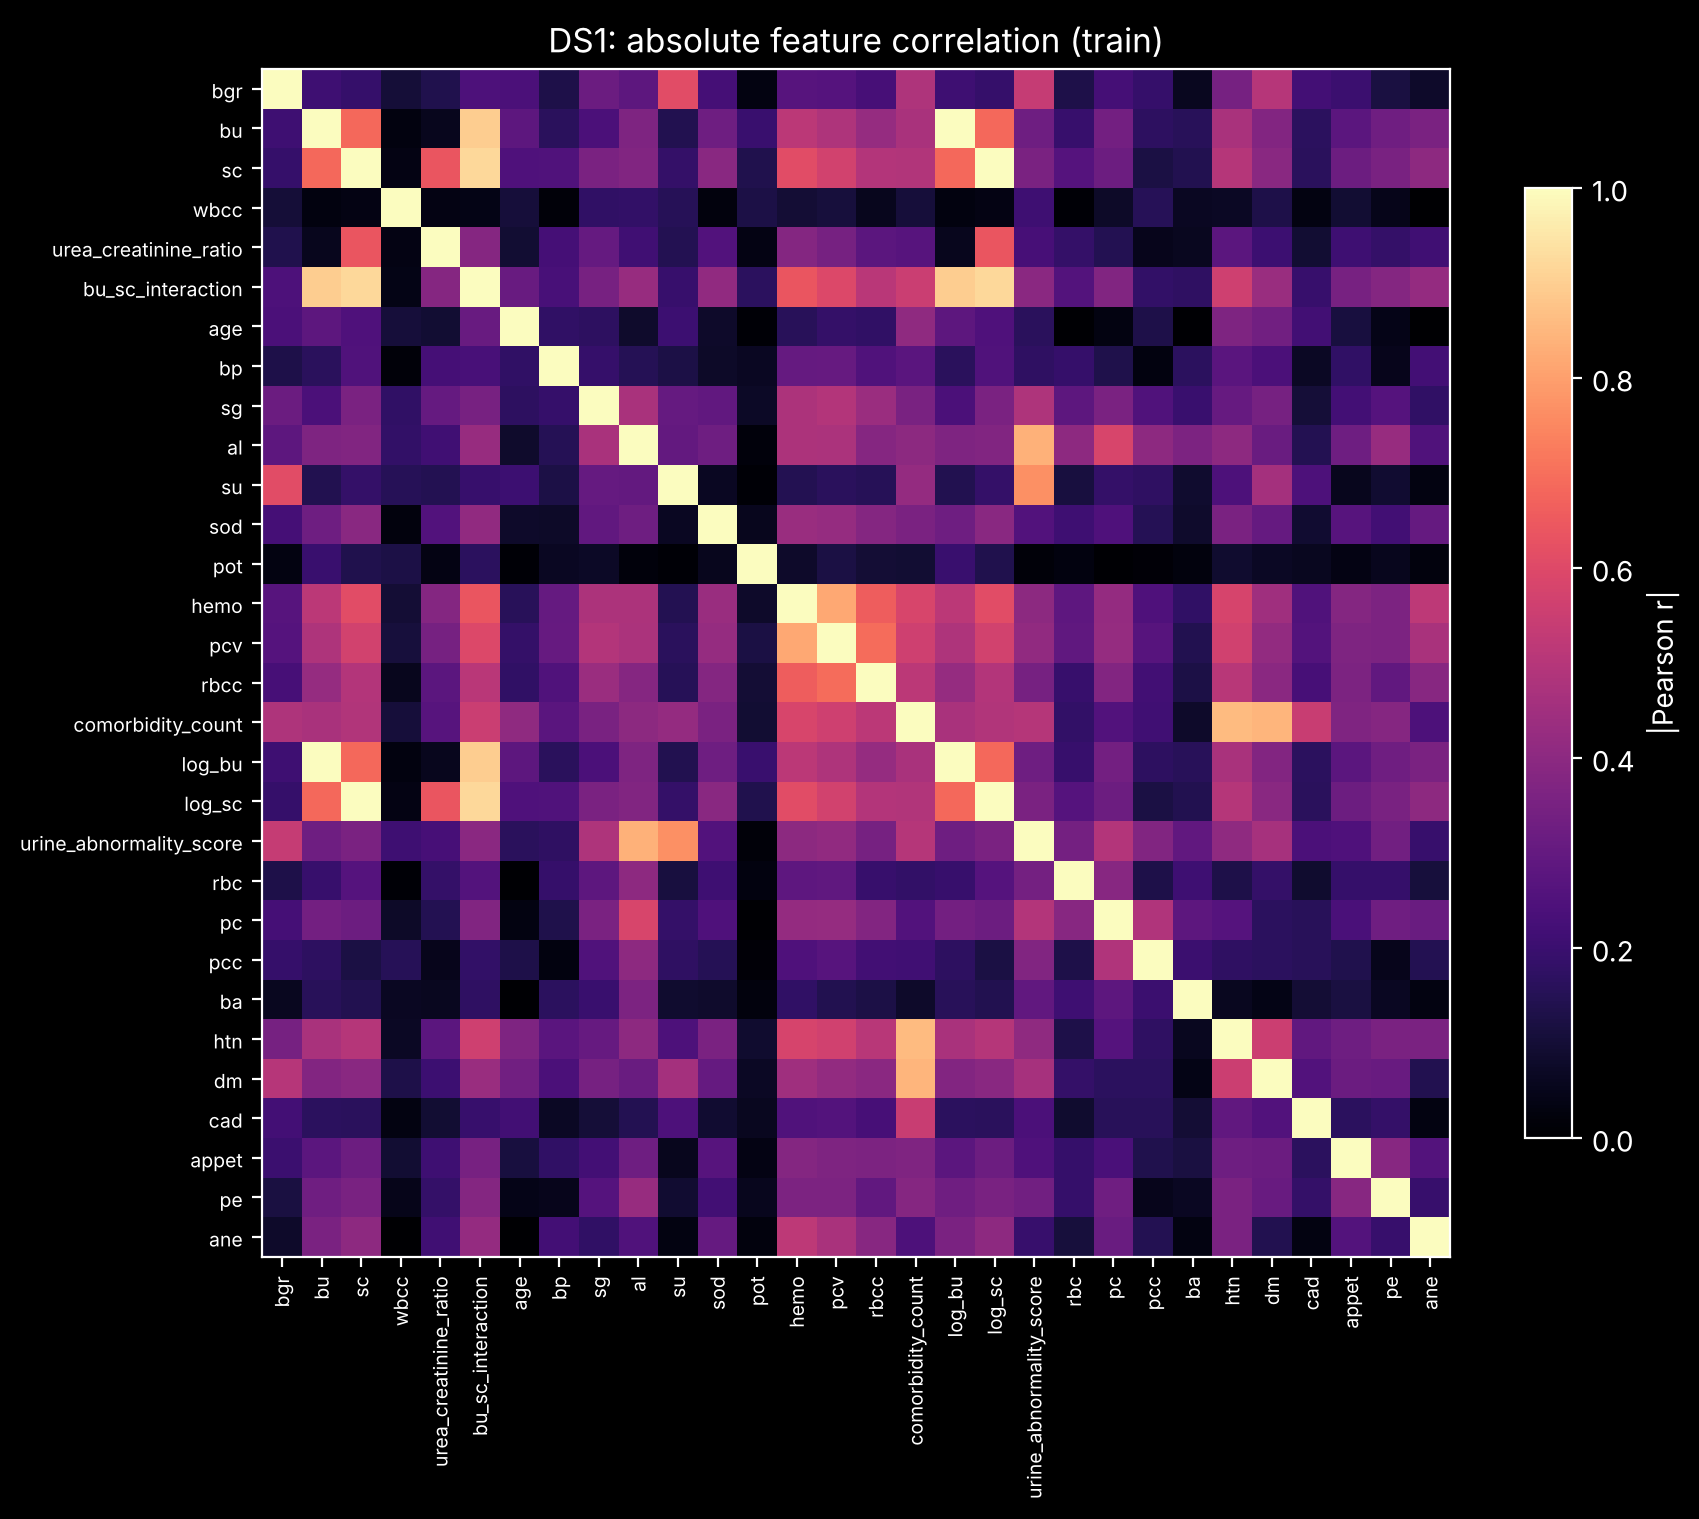

In [2]:
corr = X_train.corr().abs()
pairs = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
         .stack().sort_values(ascending=False))
print("Feature pairs with |r| > 0.8:")
print(pairs[pairs > 0.8].round(3).to_string())

plt.style.use("dark_background")
fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(corr, cmap="magma", vmin=0, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=90, fontsize=7)
ax.set_yticks(range(len(corr)), corr.columns, fontsize=7)
ax.set_title("DS1: absolute feature correlation (train)")
fig.colorbar(im, ax=ax, shrink=0.8, label="|Pearson r|")
plt.tight_layout()
plt.show()

**Observation:**
- Two pairs are exact copies in rank terms: `sc`/`log_sc` and `bu`/`log_bu` (|r| = 1.000), and `bu_sc_interaction` correlates 0.90 to 0.92 with both
- `comorbidity_count` is built from `htn` and `dm` (0.86 and 0.85), `urine_abnormality_score` from `al` (0.84), and `hemo` and `pcv` measure the same anaemia signal (0.82)
- Gaussian NB on all 30 features therefore counts the creatinine and urea evidence several times, a direct violation of its assumption; step 5 tests whether removing such features helps

## 3. Baseline: Gaussian NB

We first train Gaussian NB with default settings on all 30 features, to get a starting score and see whether the later steps help. It is scored with 5-fold stratified cross-validation on the training set, using macro F1, which weights both classes equally.

In [3]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
baseline = GaussianNB()
scores = cross_val_score(baseline, X_train, y_train, cv=cv, scoring="f1_macro")
print("Fold scores:", scores.round(3))
print(f"Baseline 5-fold macro F1: {scores.mean():.3f} (std {scores.std():.3f})")

Fold scores: [0.919 0.919 1.    0.967 1.   ]
Baseline 5-fold macro F1: 0.961 (std 0.036)


**Observation:**
- Default Gaussian NB on all 30 features reaches a 5-fold macro F1 of 0.961 (std 0.036)
- Two folds score 0.919, so the score varies more between folds than for kNN, which is consistent with the double-counted features in step 2 making some predictions over-confident

## 4. Tune the variance smoothing

Gaussian NB has one hyperparameter, `var_smoothing`: a fraction of the largest feature variance added to every variance. Larger values flatten the per-feature likelihoods, which limits how much one extreme value or one small-variance feature can dominate the product. We try 13 values on a log scale from 1e-12 to 1 with the same 5 folds.

| Setting | Values | Meaning |
|---|---|---|
| `var_smoothing` | 1e-12 to 1, log scale | Extra variance added to each feature; larger = smoother, less confident likelihoods |

 param_var_smoothing  mean_test_score  std_test_score
              0.0000           0.9612          0.0361
              0.0000           0.9612          0.0361
              0.0000           0.9612          0.0361
              0.0000           0.9612          0.0361
              0.0000           0.9612          0.0361
              0.0000           0.9612          0.0361
              0.0000           0.9612          0.0361
              0.0000           0.9612          0.0361
              0.0001           0.9612          0.0361
              0.0010           0.9612          0.0361
              0.0100           0.9612          0.0361
              0.1000           0.9258          0.0161
              1.0000           0.8363          0.0371
Best: {'var_smoothing': np.float64(1e-12)} -> 5-fold macro F1 0.961


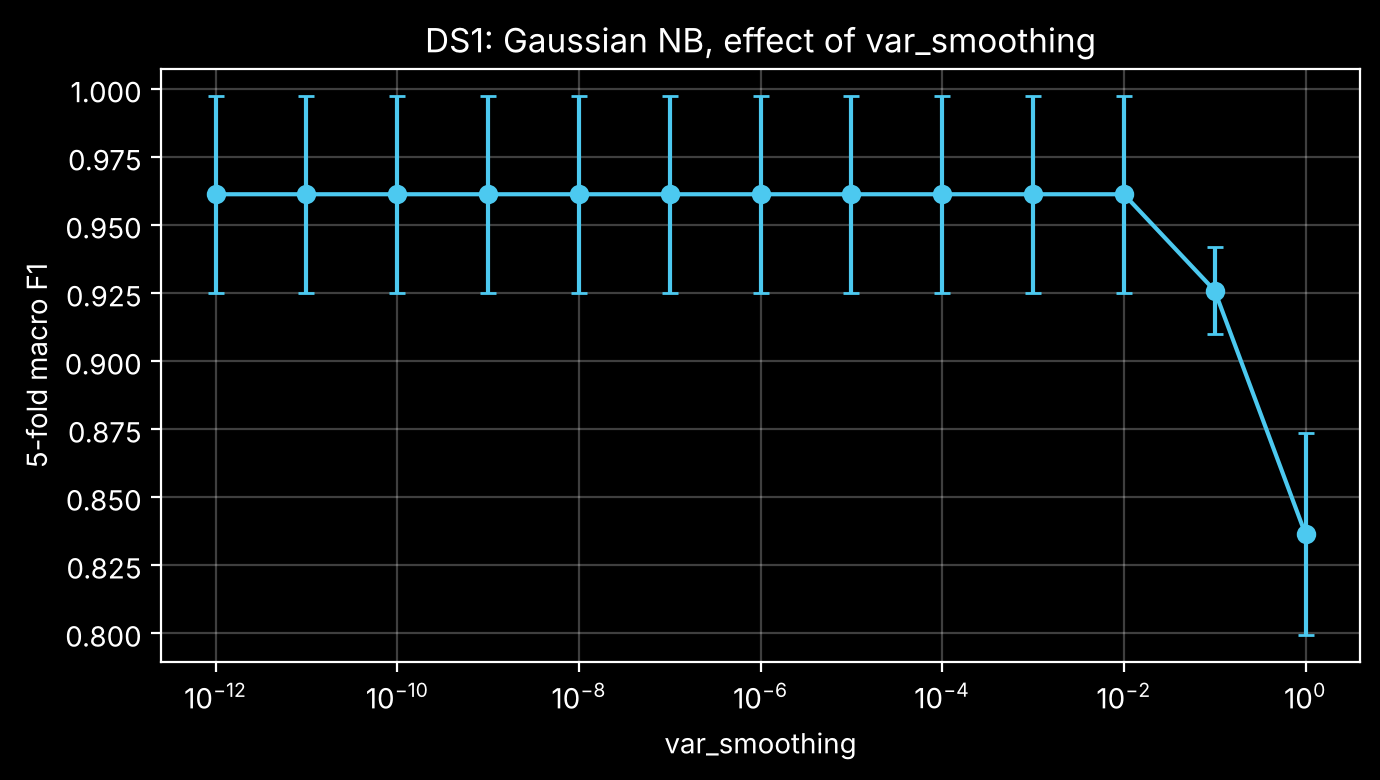

In [4]:
smoothing_grid = np.logspace(-12, 0, 13)
grid_vs = GridSearchCV(GaussianNB(), {"var_smoothing": smoothing_grid}, cv=cv, scoring="f1_macro")
grid_vs.fit(X_train, y_train)

res = pd.DataFrame(grid_vs.cv_results_)[["param_var_smoothing", "mean_test_score", "std_test_score"]]
print(res.round(4).to_string(index=False))
print(f"Best: {grid_vs.best_params_} -> 5-fold macro F1 {grid_vs.best_score_:.3f}")

plt.style.use("dark_background")
fig, ax = plt.subplots(figsize=(7, 4))
ax.errorbar(res["param_var_smoothing"].astype(float), res["mean_test_score"], yerr=res["std_test_score"],
            marker="o", color="#4cc9f0", capsize=3)
ax.set_xscale("log")
ax.set_xlabel("var_smoothing")
ax.set_ylabel("5-fold macro F1")
ax.set_title("DS1: Gaussian NB, effect of var_smoothing")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

**Observation:**
- Every value from 1e-12 to 1e-2 gives the same score (0.961), so the default (1e-9) is already in the flat region
- Larger values hurt: 0.926 at 0.1 and 0.836 at 1; the features are standardised, so these amounts are large compared with each feature's own variance and blur the class differences
- Tuning `var_smoothing` alone cannot fix the independence problem; the best value found is 1e-12, equivalent to the default

## 5. Let Naive Bayes pick its own features

Correlated and uninformative features break the independence assumption or add noise to the product of likelihoods. Here the model keeps only the features that best separate CKD from not CKD, ranked with the ANOVA F-test (`SelectKBest`). The ranking is learned inside each fold on the training part only, and the number of features (1 to all 30) is tuned together with `var_smoothing`.

Best: k = 3, var_smoothing = 1e-01 -> 5-fold macro F1 0.971 (std 0.026)
Kept: ['sg', 'hemo', 'pcv']


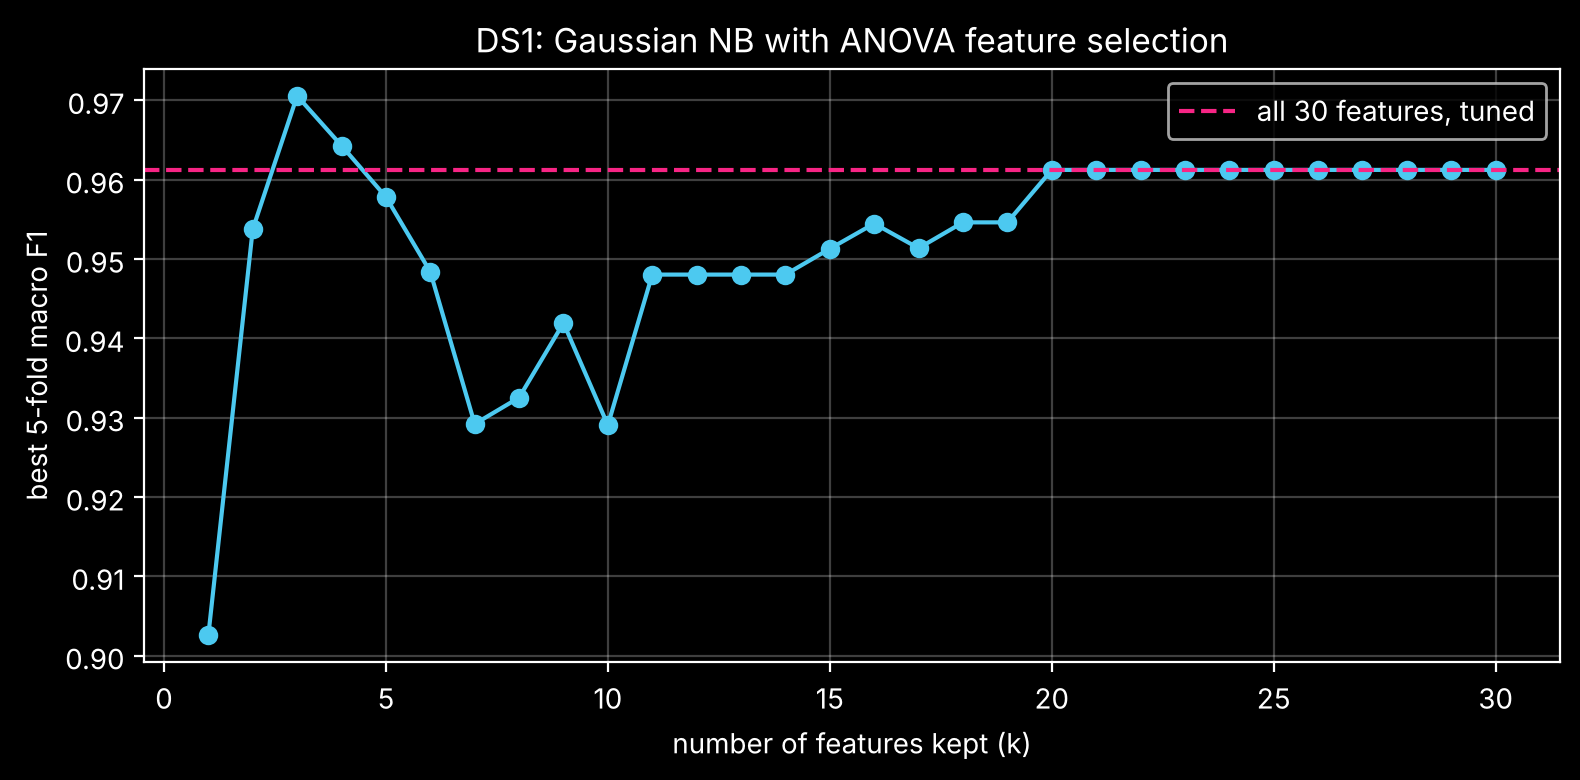

In [5]:
pipe_fs = Pipeline([("select", SelectKBest(f_classif)), ("nb", GaussianNB())])
grid_fs = GridSearchCV(
    pipe_fs,
    {"select__k": list(range(1, X_train.shape[1] + 1)), "nb__var_smoothing": smoothing_grid},
    cv=cv, scoring="f1_macro",
)
grid_fs.fit(X_train, y_train)
best_k = grid_fs.best_params_["select__k"]
kept = X_train.columns[grid_fs.best_estimator_.named_steps["select"].get_support()].tolist()
print(f"Best: k = {best_k}, var_smoothing = {grid_fs.best_params_['nb__var_smoothing']:.0e}"
      f" -> 5-fold macro F1 {grid_fs.best_score_:.3f} "
      f"(std {grid_fs.cv_results_['std_test_score'][grid_fs.best_index_]:.3f})")
print("Kept:", kept)

res_fs = pd.DataFrame(grid_fs.cv_results_)
best_per_k = res_fs.groupby("param_select__k")["mean_test_score"].max()

plt.style.use("dark_background")
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(best_per_k.index.astype(int), best_per_k.values, marker="o", color="#4cc9f0")
ax.axhline(grid_vs.best_score_, color="#f72585", ls="--", label="all 30 features, tuned")
ax.set_xlabel("number of features kept (k)")
ax.set_ylabel("best 5-fold macro F1")
ax.set_title("DS1: Gaussian NB with ANOVA feature selection")
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

**Observation:**
- The best score uses only 3 features: specific gravity (`sg`), hemoglobin (`hemo`) and packed cell volume (`pcv`), with `var_smoothing` = 0.1 (5-fold macro F1 0.971, std 0.026)
- This is above all 30 features (0.961): dropping the duplicated urea/creatinine features removes the double counting from step 2
- `hemo` and `pcv` are still correlated (0.82), so the kept set is not fully independent

## 6. Model binary features as binary (mixed NB)

Gaussian NB treats the 10 yes/no features (such as hypertension and diabetes) as if they were bell-shaped, which they are not. A mixed model uses Gaussian NB for the continuous features and Bernoulli NB for the binary ones, then adds their log-likelihoods with the class prior counted once. This is still Naive Bayes, with a likelihood that matches each feature's type. The Bernoulli smoothing `alpha` and the Gaussian `var_smoothing` are tuned together.

| Setting | Values | Meaning |
|---|---|---|
| `var_smoothing` | 1e-12 to 1, log scale | Gaussian part, as in step 4 |
| `alpha` | 0.01, 0.1, 0.5, 1, 2 | Laplace smoothing of the yes/no counts; stops a value never seen in one class from giving probability 0 |

In [6]:
class MixedNB(BaseEstimator, ClassifierMixin):
    """Gaussian NB on continuous columns + Bernoulli NB on binary columns, prior counted once."""

    def __init__(self, continuous_cols=None, binary_cols=None, var_smoothing=1e-9, alpha=1.0):
        self.continuous_cols = continuous_cols
        self.binary_cols = binary_cols
        self.var_smoothing = var_smoothing
        self.alpha = alpha

    def fit(self, X, y):
        self.gnb_ = GaussianNB(var_smoothing=self.var_smoothing).fit(X[self.continuous_cols], y)
        self.bnb_ = BernoulliNB(alpha=self.alpha, binarize=None).fit(X[self.binary_cols], y)
        self.classes_ = self.gnb_.classes_
        self.log_prior_ = np.log(self.gnb_.class_prior_)
        return self

    def _joint_log_likelihood(self, X):
        # each part's joint log-likelihood already includes log P(y); remove one copy
        X = pd.DataFrame(X)
        return (np.asarray(self.gnb_._joint_log_likelihood(X[self.continuous_cols]))
                + np.asarray(self.bnb_._joint_log_likelihood(X[self.binary_cols]))
                - self.log_prior_)

    def predict_proba(self, X):
        jll = np.asarray(self._joint_log_likelihood(X), dtype=float)
        jll = jll - jll.max(axis=1, keepdims=True)
        p = np.exp(jll)
        return p / p.sum(axis=1, keepdims=True)

    def predict(self, X):
        return self.classes_[np.argmax(self._joint_log_likelihood(X), axis=1)]


grid_mix = GridSearchCV(
    MixedNB(continuous_cols=continuous_cols, binary_cols=binary_cols),
    {"var_smoothing": smoothing_grid, "alpha": [0.01, 0.1, 0.5, 1.0, 2.0]},
    cv=cv, scoring="f1_macro",
)
grid_mix.fit(X_train, y_train)
print(f"Best: {grid_mix.best_params_} -> 5-fold macro F1 {grid_mix.best_score_:.3f} "
      f"(std {grid_mix.cv_results_['std_test_score'][grid_mix.best_index_]:.3f})")

Best: {'alpha': 0.01, 'var_smoothing': np.float64(0.01)} -> 5-fold macro F1 0.951 (std 0.023)


**Observation:**
- The mixed model scores 0.951 (std 0.023), below plain Gaussian NB on all 30 features (0.961)
- Modelling the yes/no flags with the correct distribution does not help here, because the mixed model still uses all 30 features, including the duplicated ones, and `comorbidity_count` repeats `htn` and `dm` across the two parts

## 7. Check the scores are stable

Steps 4 to 6 each picked their best out of many settings on the same 5 folds, so their scores are a little optimistic. To compare them fairly, we score the best version of each again with 10 different 5-fold splits (50 scores per version). The version with the highest mean becomes the final model.

                              mean    std    min
Baseline (default, all 30)   0.961  0.026  0.888
Tuned smoothing (all 30)     0.960  0.025  0.888
Own feature selection (k=3)  0.966  0.025  0.888
Mixed Gaussian + Bernoulli   0.953  0.025  0.888

Final model: Own feature selection (k=3)


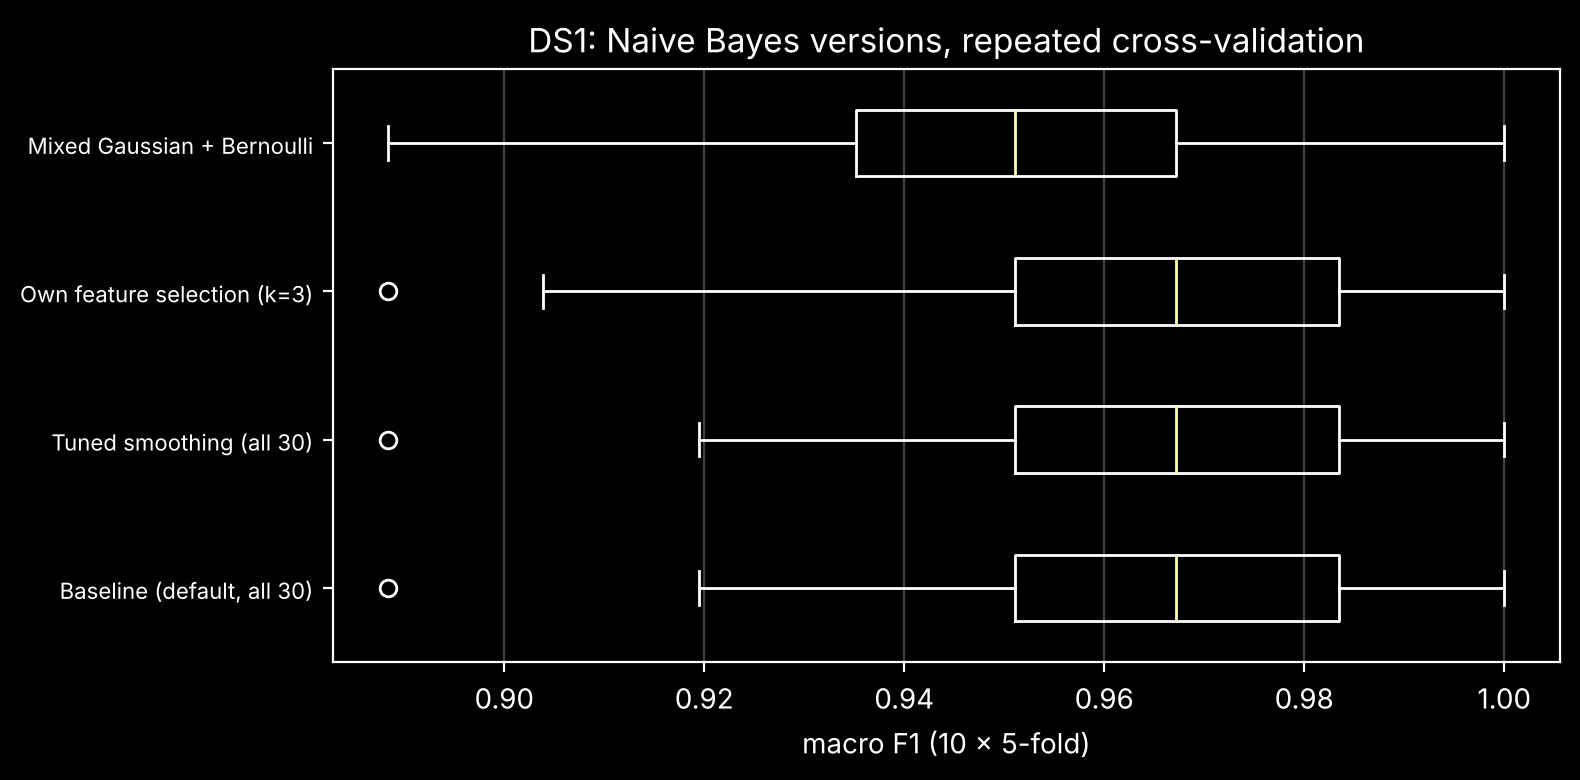

In [7]:
rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=RANDOM_STATE)
versions = {
    "Baseline (default, all 30)": GaussianNB(),
    "Tuned smoothing (all 30)": grid_vs.best_estimator_,
    f"Own feature selection (k={best_k})": grid_fs.best_estimator_,
    "Mixed Gaussian + Bernoulli": grid_mix.best_estimator_,
}
repeated = {name: cross_val_score(m, X_train, y_train, cv=rcv, scoring="f1_macro") for name, m in versions.items()}
rep_df = pd.DataFrame({n: [s.mean(), s.std(), s.min()] for n, s in repeated.items()},
                      index=["mean", "std", "min"]).T
print(rep_df.round(3).to_string())

final_name = rep_df["mean"].idxmax()
final_model = versions[final_name]
print("\nFinal model:", final_name)

plt.style.use("dark_background")
fig, ax = plt.subplots(figsize=(8, 4))
ax.boxplot(list(repeated.values()), orientation="horizontal")
ax.set_yticks(range(1, len(repeated) + 1), list(repeated.keys()), fontsize=8)
ax.set_xlabel("macro F1 (10 x 5-fold)")
ax.set_title("DS1: Naive Bayes versions, repeated cross-validation")
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

**Observation:**
- Repeated cross-validation keeps the same order: own feature selection 0.966, baseline 0.961, tuned smoothing 0.960, mixed 0.953
- The gaps (at most 0.014) are smaller than the spread of each version (std about 0.025), so the versions are close; all four share the same worst split (0.888)
- Own feature selection has the highest mean and becomes the final model, as decided in advance; it also needs only 3 measurements

## 8. Look at the errors on the training folds

The test set is small, so we also look at the 320 out-of-fold predictions of the final model on the training set to see where Naive Bayes fails. For each error, we show the predicted CKD probability. Naive Bayes is known to give over-confident probabilities when features are correlated, so the confidence of the errors is worth checking.

Correct out-of-fold: 311 / 320
       true predicted  P(ckd)
34      ckd    notckd  0.4840
43      ckd    notckd  0.0418
165     ckd    notckd  0.2796
183     ckd    notckd  0.2165
188     ckd    notckd  0.1126
257  notckd       ckd  0.5706
264     ckd    notckd  0.1236
276     ckd    notckd  0.1969
282     ckd    notckd  0.3674


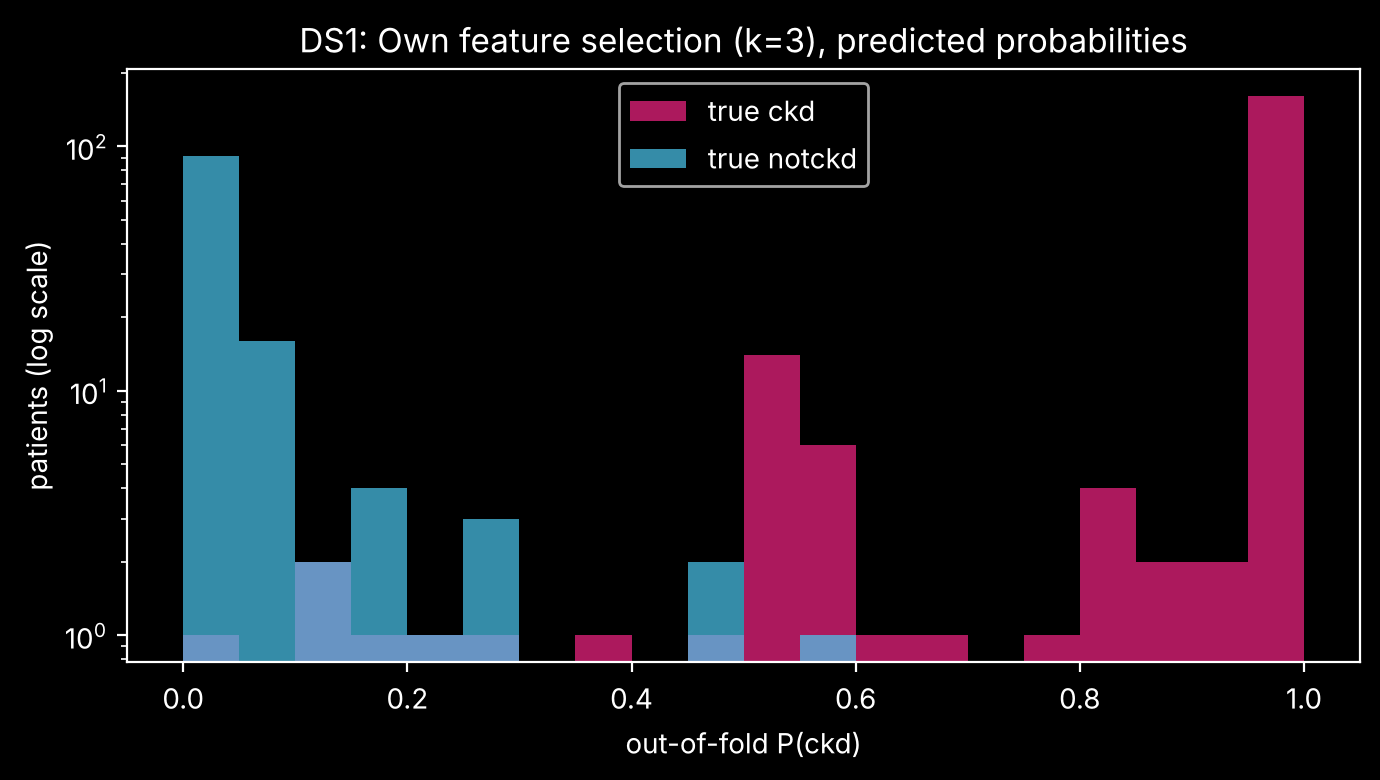

In [8]:
oof_proba = cross_val_predict(final_model, X_train, y_train, cv=cv, method="predict_proba")[:, 0]
oof_pred = np.where(oof_proba >= 0.5, 0, 1)
wrong = np.flatnonzero(oof_pred != y_train.values)
print(f"Correct out-of-fold: {len(y_train) - len(wrong)} / {len(y_train)}")

errors = pd.DataFrame({
    "true": [class_order[i] for i in y_train.values[wrong]],
    "predicted": [class_order[i] for i in oof_pred[wrong]],
    "P(ckd)": oof_proba[wrong].round(4),
}, index=wrong)
print(errors.to_string())

plt.style.use("dark_background")
fig, ax = plt.subplots(figsize=(7, 4))
bins = np.linspace(0, 1, 21)
for cls, color in [(0, "#f72585"), (1, "#4cc9f0")]:
    ax.hist(oof_proba[y_train.values == cls], bins=bins, alpha=0.7, color=color, label=f"true {class_order[cls]}")
ax.set_yscale("log")
ax.set_xlabel("out-of-fold P(ckd)")
ax.set_ylabel("patients (log scale)")
ax.set_title(f"DS1: {final_name}, predicted probabilities")
ax.legend()
plt.tight_layout()
plt.show()

**Observation:**
- The final model gets 311 of 320 training patients right when they are held out
- 8 of the 9 errors are CKD patients predicted as not CKD, the more costly error in screening; one is a confident miss (P(ckd) = 0.04)
- With only 3 features, a CKD patient whose hemoglobin, packed cell volume and specific gravity look normal has no other evidence that could flag them

## 9. Evaluate the final model on the test set

The final model is refitted on all 320 training patients and tested once on the 80 test patients. The test set played no part in any choice, so this is a fair estimate for new patients. We report accuracy, macro F1, ROC AUC (how well the CKD probability ranks patients), per-class precision and recall, and the confusion matrix.

Accuracy:  0.9375
Macro F1:  0.9329
ROC AUC:   0.9820

              precision    recall  f1-score   support

         ckd      0.941     0.960     0.950        50
      notckd      0.931     0.900     0.915        30

    accuracy                          0.938        80
   macro avg      0.936     0.930     0.933        80
weighted avg      0.937     0.938     0.937        80



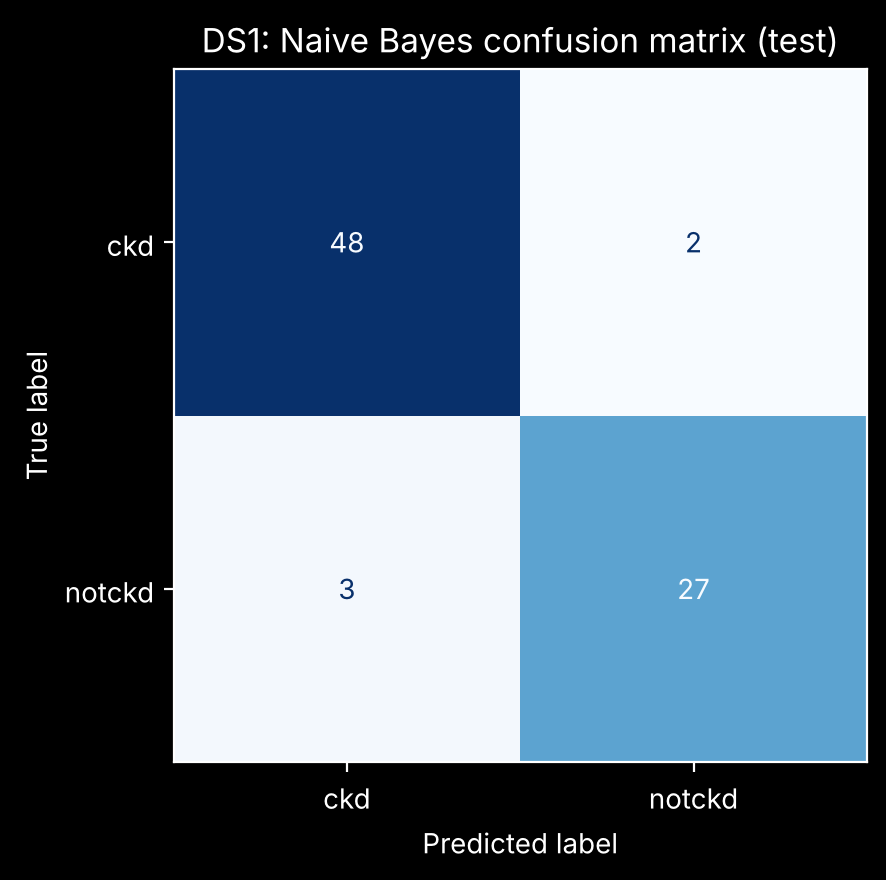

In [9]:
final_model.fit(X_train, y_train)
y_pred = final_model.predict(X_test)
p_ckd = final_model.predict_proba(X_test)[:, 0]

print(f"Accuracy:  {accuracy_score(y_test, y_pred):.4f}")
print(f"Macro F1:  {f1_score(y_test, y_pred, average='macro'):.4f}")
print(f"ROC AUC:   {roc_auc_score(y_test == 0, p_ckd):.4f}")
print()
print(classification_report(y_test, y_pred, target_names=class_order, digits=3, zero_division=0))

plt.style.use("dark_background")
fig, ax = plt.subplots(figsize=(5, 4.5))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=class_order).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title(f"DS1: Naive Bayes confusion matrix (test)")
plt.tight_layout()
plt.show()

**Observation:**
- On the 80 test patients the final model reaches accuracy 0.938, macro F1 0.933 and ROC AUC 0.982
- 48 of 50 CKD patients are caught (recall 0.960) and 27 of 30 healthy patients are cleared (recall 0.900): 2 missed CKD cases and 3 false alarms
- This is below the 0.966 from repeated cross-validation; with 80 patients one error costs 0.0125 accuracy, so the gap is 2 to 3 patients and within the range seen across folds (minimum 0.888)

## 10. Compare all versions

Finally, all versions are put in one table to show what each step added. The final model was chosen on the repeated cross-validation score; test scores are shown for reference only.

In [10]:
rows = []
for name, m in versions.items():
    m.fit(X_train, y_train)
    pred = m.predict(X_test)
    rows.append({
        "version": name,
        "repeated CV macro F1": repeated[name].mean(),
        "CV std": repeated[name].std(),
        "test accuracy": accuracy_score(y_test, pred),
        "test macro F1": f1_score(y_test, pred, average="macro"),
        "test ROC AUC": roc_auc_score(y_test == 0, m.predict_proba(X_test)[:, 0]),
    })
summary = pd.DataFrame(rows).set_index("version")
print(summary.round(4).to_string())

                             repeated CV macro F1  CV std  test accuracy  test macro F1  test ROC AUC
version                                                                                              
Baseline (default, all 30)                 0.9610  0.0259         0.9750         0.9737         1.000
Tuned smoothing (all 30)                   0.9600  0.0255         0.9625         0.9607         1.000
Own feature selection (k=3)                0.9662  0.0252         0.9375         0.9329         0.982
Mixed Gaussian + Bernoulli                 0.9526  0.0247         0.9875         0.9868         1.000


**Observation:**
- The ranking on the test set is the reverse of cross-validation: the mixed model scores best on test (macro F1 0.987) and the chosen 3-feature model scores worst (0.933)
- This shows how noisy 80 test patients are: the cross-validation differences were within one standard deviation, and the test differences are 1 to 4 patients. The choice stays with cross-validation, because choosing on the test set would leak it into model selection
- All 30-feature versions rank patients perfectly on test (ROC AUC 1.000), so most of their errors come from the 0.5 threshold, not from the ordering of probabilities

**Summary:** Naive Bayes on DS1 reaches a repeated 5-fold macro F1 of 0.953 to 0.966 across versions and 0.933 to 0.987 macro F1 on the test set, below kNN (0.993 repeated CV) and Random Forest (0.987 test). Its main weakness on this data is the independence assumption, which the engineered features break; its strengths are speed, no need for distance or scaling, and a model that can be read directly as class-wise means and variances.

## 11. Practical application and related work

**Where Naive Bayes fits in CKD screening**
- Training is a single pass that stores one mean and variance (or one yes/no rate) per feature and class, and prediction is a sum of log-likelihoods, so it runs on any clinic hardware and retrains instantly as new patients arrive
- The model is directly readable: a clinician can see, for example, how far the CKD mean for hemoglobin sits from the healthy mean, which supports explaining a prediction
- It can still predict when some measurements are missing, since each feature contributes its own term; this would suit clinics that do not run every test
- The final model needs only three routine measurements (urine specific gravity, hemoglobin, packed cell volume), which makes it a cheap first-line screen

**Limits seen in this notebook**
- Most errors are missed CKD cases (step 8), so as a screen it should be run with a lower decision threshold than 0.5 or followed by a second test; the ROC AUC of 0.98 to 1.00 shows the probabilities rank patients well even when the 0.5 cut-off errs
- Its probabilities are pushed towards 0 and 1 when features are correlated (step 2), so they should not be read as calibrated risk scores without calibration

**Related work**
- Domingos and Pazzani [1] show that Naive Bayes can classify well even when the independence assumption is violated, because only the ranking of the class scores has to be right, not the probabilities; this matches the high ROC AUC here despite correlated features
- Zhang [2] argues that what harms Naive Bayes is how the dependencies are distributed across classes rather than their mere presence, which is consistent with the duplicated urea/creatinine features lowering the score while dropping them helps (step 5)
- The dataset is the UCI Chronic Kidney Disease dataset [3]; all models use scikit-learn [4]

**References**

[1] P. Domingos and M. Pazzani, "On the optimality of the simple Bayesian classifier under zero-one loss," *Machine Learning*, vol. 29, pp. 103-130, 1997. https://doi.org/10.1023/A:1007413511361

[2] H. Zhang, "The optimality of Naive Bayes," in *Proc. 17th Int. Florida Artificial Intelligence Research Society Conf. (FLAIRS)*, AAAI Press, pp. 562-567, 2004.

[3] L. Rubini, P. Soundarapandian, and P. Eswaran, "Chronic Kidney Disease," UCI Machine Learning Repository, 2015. https://doi.org/10.24432/C5G020

[4] F. Pedregosa et al., "Scikit-learn: Machine learning in Python," *Journal of Machine Learning Research*, vol. 12, pp. 2825-2830, 2011.